# 09 · Evaluación por toalla, ensamble y umbral de operación

Este es el notebook que responde la pregunta de negocio: **¿qué porcentaje de toallas con defecto se detecta, y cuántas toallas OK se mandan a revisión por error?**

- Cada modelo da un score por toalla: YOLO (máxima confianza de un defecto), clasificador (máxima probabilidad por recorte) y PatchCore (máxima anomalía dentro de la toalla).
- Los ensambles y los umbrales se ajustan **solo en validación**. Las métricas finales se reportan sobre las toallas de **test**, que ningún modelo vio.
- **Calibración por cámara:** la escala de los scores cambia con la cámara (luz, distancia, sensor). Cada score se normaliza contra las toallas OK de validación **de la misma cámara**. En producción se usa la calibración de la cámara de junio 2025.
- **Umbral de operación:** se elige para alcanzar un recall ≥ 98 % de toallas NO OK en validación. Detectar defectos es la prioridad; el costo es revisar a mano algunas toallas OK.

```bash
python scripts/08_evaluate.py     # calcula los scores, ajusta el ensamble y escribe reports/metrics.md
```

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from galia import config as C, viz
from galia.ensemble import Ensemble, metrics_at
from galia.data import load_manifest, load_image, load_boxes
viz.setup()
val = pd.read_csv(C.REPORTS_DIR / "scores_val.csv", keep_default_na=False)
test = pd.read_csv(C.REPORTS_DIR / "scores_test.csv", keep_default_na=False)
metrics = json.loads((C.REPORTS_DIR / "metrics.json").read_text(encoding="utf-8"))
ens = {n: Ensemble.load(C.REPORTS_DIR / f"ensemble_{n}.json") for n in metrics["results"]}
SEL = metrics["selected"]
OP = metrics["target"]          # punto de operación por defecto (recall_98)
yv, yt = (val.label == "NG").astype(int).to_numpy(), (test.label == "NG").astype(int).to_numpy()
print(f"Validación: {len(val)} toallas ({yv.sum()} NO OK) · Test: {len(test)} toallas ({yt.sum()} NO OK)")
print(f"Método seleccionado en validación: {SEL}")

Validación: 230 toallas (73 NO OK) · Test: 231 toallas (74 NO OK)
Método seleccionado en validación: cls


## 1. Resumen: punto de operación recall ≥ 98 % (fijado en validación)

In [2]:
rows = []
for n, r in metrics["results"].items():
    t = r[OP]["test"]; v = r[OP]["val"]
    rows.append({"método": viz.MODEL_NAMES[n], "recall NO OK (test)": t["recall_ng"],
                 "toallas NO OK detectadas": f"{t['tp']}/{t['tp'] + t['fn']}",
                 "falsas alarmas OK (test)": t["false_alarm_rate_ok"],
                 "OK enviadas a revisión": f"{t['fp']}/{t['fp'] + t['tn']}",
                 "AUC (test)": t["auc"], "falsas alarmas OK (val)": v["false_alarm_rate_ok"]})
summary = pd.DataFrame(rows).set_index("método")
summary.style.format({"recall NO OK (test)": "{:.1%}", "falsas alarmas OK (test)": "{:.1%}",
                      "falsas alarmas OK (val)": "{:.1%}", "AUC (test)": "{:.3f}"})

,recall NO OK (test),toallas NO OK detectadas,falsas alarmas OK (test),OK enviadas a revisión,AUC (test),falsas alarmas OK (val)
método,,,,,,
YOLO11s (recortes),91.9%,68/74,74.5%,117/157,0.815,65.6%
EfficientNet-B0 (recortes),89.2%,66/74,23.6%,37/157,0.900,28.7%
PatchCore,97.3%,72/74,79.0%,124/157,0.756,82.8%
Ensamble (máx.),94.6%,70/74,35.7%,56/157,0.911,42.0%
Ensamble (logístico),100.0%,74/74,94.9%,149/157,0.897,93.6%


## 2. Por qué calibrar por cámara
El mismo clasificador da scores más altos a las toallas OK de junio que a las de abril (otra luz y otro fondo). Con un único umbral global, casi todas las toallas OK de junio, que es la cámara de producción, saldrían como NO OK.

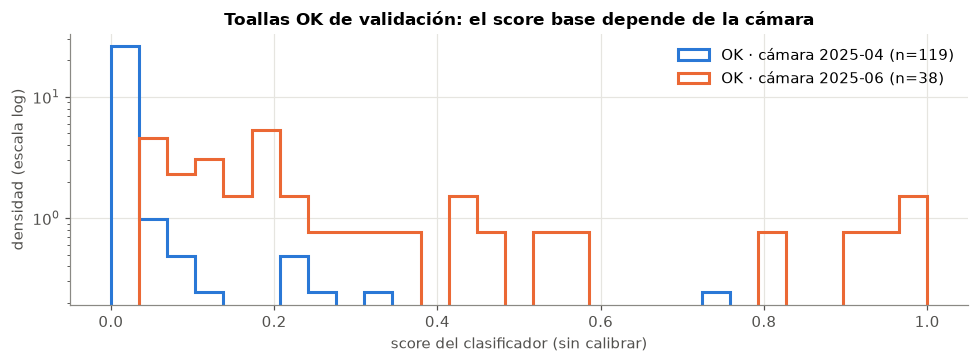

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(0, 1, 30)
for (cap, lab), g in val.groupby(["capture", "label"]):
    if lab == "OK":
        ax.hist(g.cls, bins=bins, histtype="step", lw=2, density=True, label=f"OK · cámara {cap} (n={len(g)})",
                color=viz.PALETTE[0] if cap == "2025-04" else viz.PALETTE[1])
ax.set_yscale("log"); ax.set_xlabel("score del clasificador (sin calibrar)"); ax.set_ylabel("densidad (escala log)"); ax.legend()
ax.set_title("Toallas OK de validación: el score base depende de la cámara")
plt.tight_layout()

## 3. Cuánto separa cada modelo las toallas OK de las NO OK (test, score calibrado)

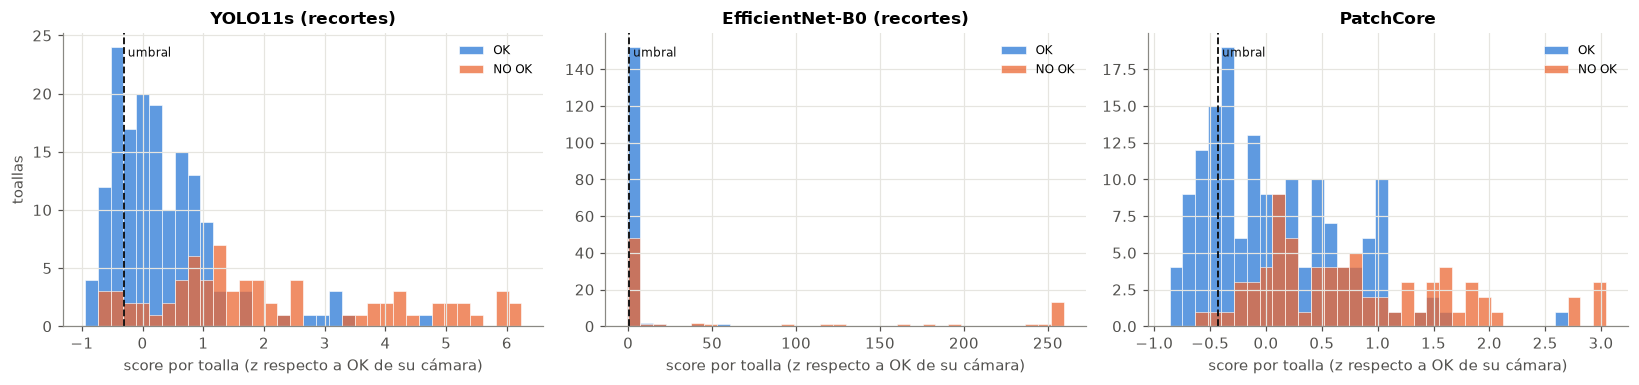

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, m in zip(axes, ["yolo", "cls", "patchcore"]):
    z = ens[m].score(test)
    lo, hi = np.percentile(z, [0, 99.5])
    bins = np.linspace(lo, hi, 35)
    for lab, name in [("OK", "OK"), ("NG", "NO OK")]:
        ax.hist(np.clip(z[(test.label == lab).to_numpy()], lo, hi), bins=bins, alpha=0.75, color=viz.LABEL_COLORS[lab], label=name,
                edgecolor="white", linewidth=0.5)
    thr = ens[m].thresholds[OP]
    ax.axvline(thr, color="#0b0b0b", lw=1.2, ls="--")
    ax.text(thr, ax.get_ylim()[1] * 0.92, " umbral", fontsize=8, color="#0b0b0b")
    ax.set_title(viz.MODEL_NAMES[m]); ax.set_xlabel("score por toalla (z respecto a OK de su cámara)"); ax.legend(fontsize=8)
axes[0].set_ylabel("toallas")
plt.tight_layout()

## 4. Curvas ROC por toalla (test)
El eje Y es el recall de toallas NO OK y el eje X la fracción de toallas OK marcadas por error. Los puntos marcan el umbral elegido en validación.

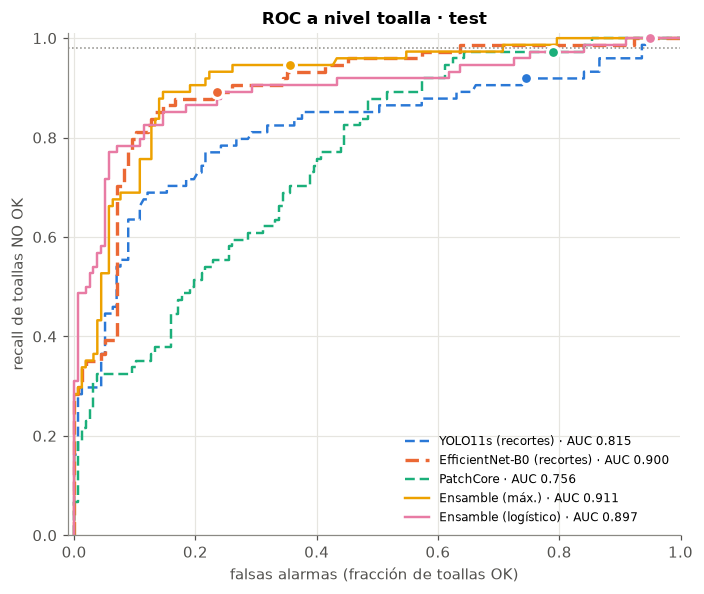

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for n, e in ens.items():
    s = e.score(test)
    fpr, tpr, _ = roc_curve(yt, s)
    ls = "-" if n in ("max", "logistic") else (0, (4, 2))
    ax.plot(fpr, tpr, color=viz.MODEL_COLORS[n], ls=ls, lw=2.2 if n == SEL else 1.6,
            label=f"{viz.MODEL_NAMES[n]} · AUC {roc_auc_score(yt, s):.3f}")
    mt = metrics_at(s, yt, e.thresholds[OP])
    ax.scatter(mt["false_alarm_rate_ok"], mt["recall_ng"], s=60, color=viz.MODEL_COLORS[n], edgecolor="white", linewidth=2, zorder=5)
ax.axhline(0.98, color="#8a8984", lw=1, ls=":")
ax.set_xlabel("falsas alarmas (fracción de toallas OK)"); ax.set_ylabel("recall de toallas NO OK")
ax.set_xlim(-0.01, 1); ax.set_ylim(0, 1.01); ax.legend(loc="lower right", fontsize=8)
ax.set_title("ROC a nivel toalla · test")
plt.tight_layout()

## 5. Elegir el punto de operación
El umbral es una decisión de negocio. Más recall implica revisar a mano más toallas OK. Esta tabla muestra el resultado en test para el método seleccionado con tres objetivos de recall fijados en validación.

In [6]:
op = []
for k in ["recall_90", "recall_95", "recall_98"]:
    t = metrics["results"][SEL][k]["test"]
    op.append({"objetivo (val)": k.replace("recall_", "") + " %", "umbral": t["threshold"],
               "recall NO OK (test)": f"{t['recall_ng']:.1%} ({t['tp']}/{t['tp'] + t['fn']})",
               "falsas alarmas OK (test)": f"{t['false_alarm_rate_ok']:.1%} ({t['fp']}/{t['fp'] + t['tn']})",
               "precisión NO OK": f"{t['precision_ng']:.1%}"})
pd.DataFrame(op).set_index("objetivo (val)")

,umbral,recall NO OK (test),falsas alarmas OK (test),precisión NO OK
objetivo (val),,,,
90 %,1.485959,81.1% (60/74),11.5% (18/157),76.9%
95 %,0.926059,86.5% (64/74),16.6% (26/157),71.1%
98 %,0.562219,89.2% (66/74),23.6% (37/157),64.1%


## 6. Solo la cámara de producción (junio 2025, test)
Es el escenario real de la línea. Son 77 toallas (40 NO OK), así que cada toalla equivale a 2.5 puntos de recall.

In [7]:
op = []
for k in ["recall_90", "recall_95", "recall_98"]:
    t = metrics["results"][SEL][k]["test_produccion"]
    op.append({"objetivo (val)": k.replace("recall_", "") + " %",
               "recall NO OK": f"{t['recall_ng']:.1%} ({t['tp']}/{t['tp'] + t['fn']})",
               "falsas alarmas OK": f"{t['false_alarm_rate_ok']:.1%} ({t['fp']}/{t['fp'] + t['tn']})",
               "precisión NO OK": f"{t['precision_ng']:.1%}"})
pd.DataFrame(op).set_index("objetivo (val)")

,recall NO OK,falsas alarmas OK,precisión NO OK
objetivo (val),,,
90 %,72.5% (29/40),10.8% (4/37),87.9%
95 %,80.0% (32/40),16.2% (6/37),84.2%
98 %,85.0% (34/40),27.0% (10/37),77.3%


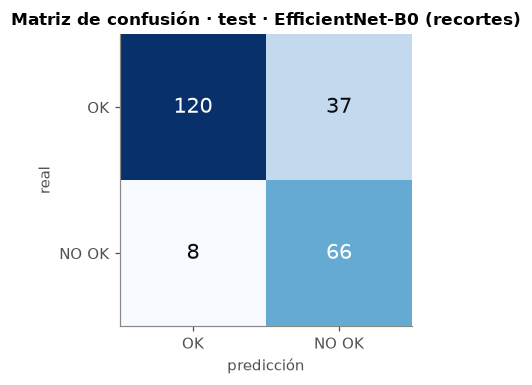

In [8]:
s_sel = ens[SEL].score(test)
thr = ens[SEL].thresholds[OP]
pred = s_sel >= thr
cm = pd.crosstab(pd.Series(np.where(yt == 1, "NO OK", "OK"), name="real"),
                 pd.Series(np.where(pred, "NO OK", "OK"), name="predicción")).reindex(index=["OK", "NO OK"], columns=["OK", "NO OK"]).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm.to_numpy(), cmap="Blues"); ax.grid(False)
for i in range(2):
    for j in range(2):
        v = cm.iat[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=14, color="white" if v > cm.to_numpy().max() / 2 else "#0b0b0b")
ax.set_xticks([0, 1], cm.columns); ax.set_yticks([0, 1], cm.index)
ax.set_xlabel("predicción"); ax.set_ylabel("real"); ax.set_title(f"Matriz de confusión · test · {viz.MODEL_NAMES[SEL]}")
plt.tight_layout()

## 7. ¿Qué defectos se escapan? Recall por categoría, fuente y visibilidad (test)
> **Ojo con "No visible":** que el modelo marque toallas cuyo defecto "no es visible" puede significar que el defecto sí deja rastro en la foto, o que el modelo aprovecha diferencias de la sesión de captura de abril. Con 10 toallas no se puede distinguir; conviene revisarlo con más datos.

,n,falsas alarmas OK
C,37.0,0.27027
D,120.0,0.22500


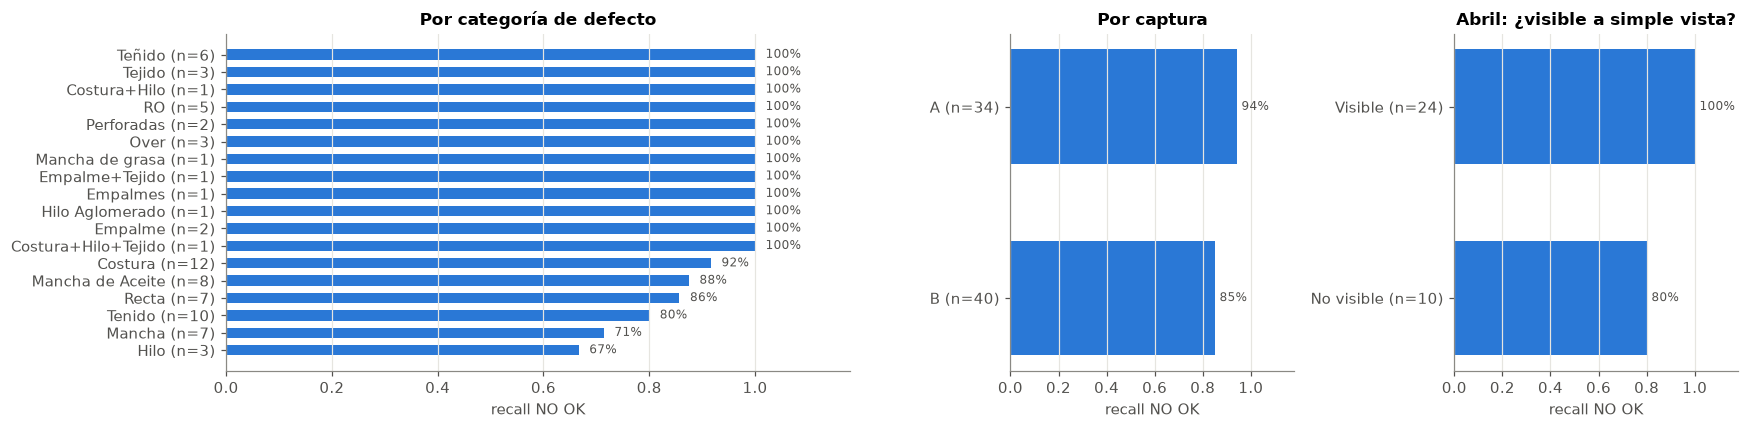

In [9]:
t = metrics["results"][SEL][OP]["test"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))
for ax, key, title in [(axes[0], "by_category", "Por categoría de defecto"),
                       (axes[1], "by_source", "Por captura"),
                       (axes[2], "by_visibility", "Abril: ¿visible a simple vista?")]:
    d = pd.DataFrame(t[key]).T.sort_values("recall")
    ax.barh([f"{k} (n={int(v.n)})" for k, v in d.iterrows()], d.recall, color=viz.PALETTE[0], height=0.6)
    for yy, v in enumerate(d.recall):
        ax.text(v + 0.02, yy, f"{v:.0%}", va="center", fontsize=8, color="#52514e")
    ax.set_xlim(0, 1.18); ax.grid(axis="y", visible=False); ax.set_title(title); ax.set_xlabel("recall NO OK")
plt.tight_layout()
pd.DataFrame(t["false_alarm_by_source"]).T.rename(columns={"false_alarm": "falsas alarmas OK"})

## 8. Toallas NO OK no detectadas (falsos negativos en test)

In [10]:
from galia.models import PatchcorePredictor
dets = json.loads((C.REPORTS_DIR / "yolo_detections_test.json").read_text())
man = load_manifest().set_index("image_id")
fn = test[(yt == 1) & ~pred].copy(); fn["score"] = s_sel[(yt == 1) & ~pred]
print(f"{len(fn)} toallas NO OK sin detectar de {yt.sum()}")
fn[["image_id", "source", "visibility", "category", "yolo", "cls", "patchcore", "score"]].round(3)

8 toallas NO OK sin detectar de 74


,image_id,source,visibility,category,yolo,cls,patchcore,score
4,A_15d746e6-20250402_162840400_0000000004_T0000...,A,No visible,Mancha de Aceite,0.864,0.002,48.747,0.207
16,A_69856ff6-20250402_165001408_0000000008_T0000...,A,No visible,Recta,0.159,0.002,40.221,0.278
42,B_51c9238c-2025-06-20T14_52_09.764865,B,Visible,Hilo,0.492,0.200,46.121,0.044
45,B_6aca64f4-2025-06-20T14_26_52.525715,B,Visible,Mancha,0.209,0.180,49.668,-0.026
48,B_7d2885ac-2025-06-20T14_40_41.769990,B,Visible,Costura,0.084,0.162,63.400,-0.088
55,B_9c88576a-2025-06-23T12_59_38.987047,B,Visible,Mancha,0.127,0.307,45.173,0.417
59,B_aa9dc0bc-2025-06-20T14_42_46.868812,B,Visible,Tenido,0.030,0.146,47.753,-0.146
67,B_d2f4c2d1-2025-06-23T12_43_43.800876,B,Visible,Tenido,0.225,0.102,44.148,-0.298


Verde: defecto anotado · Rojo: detecciones de YOLO con conf ≥ 0.10


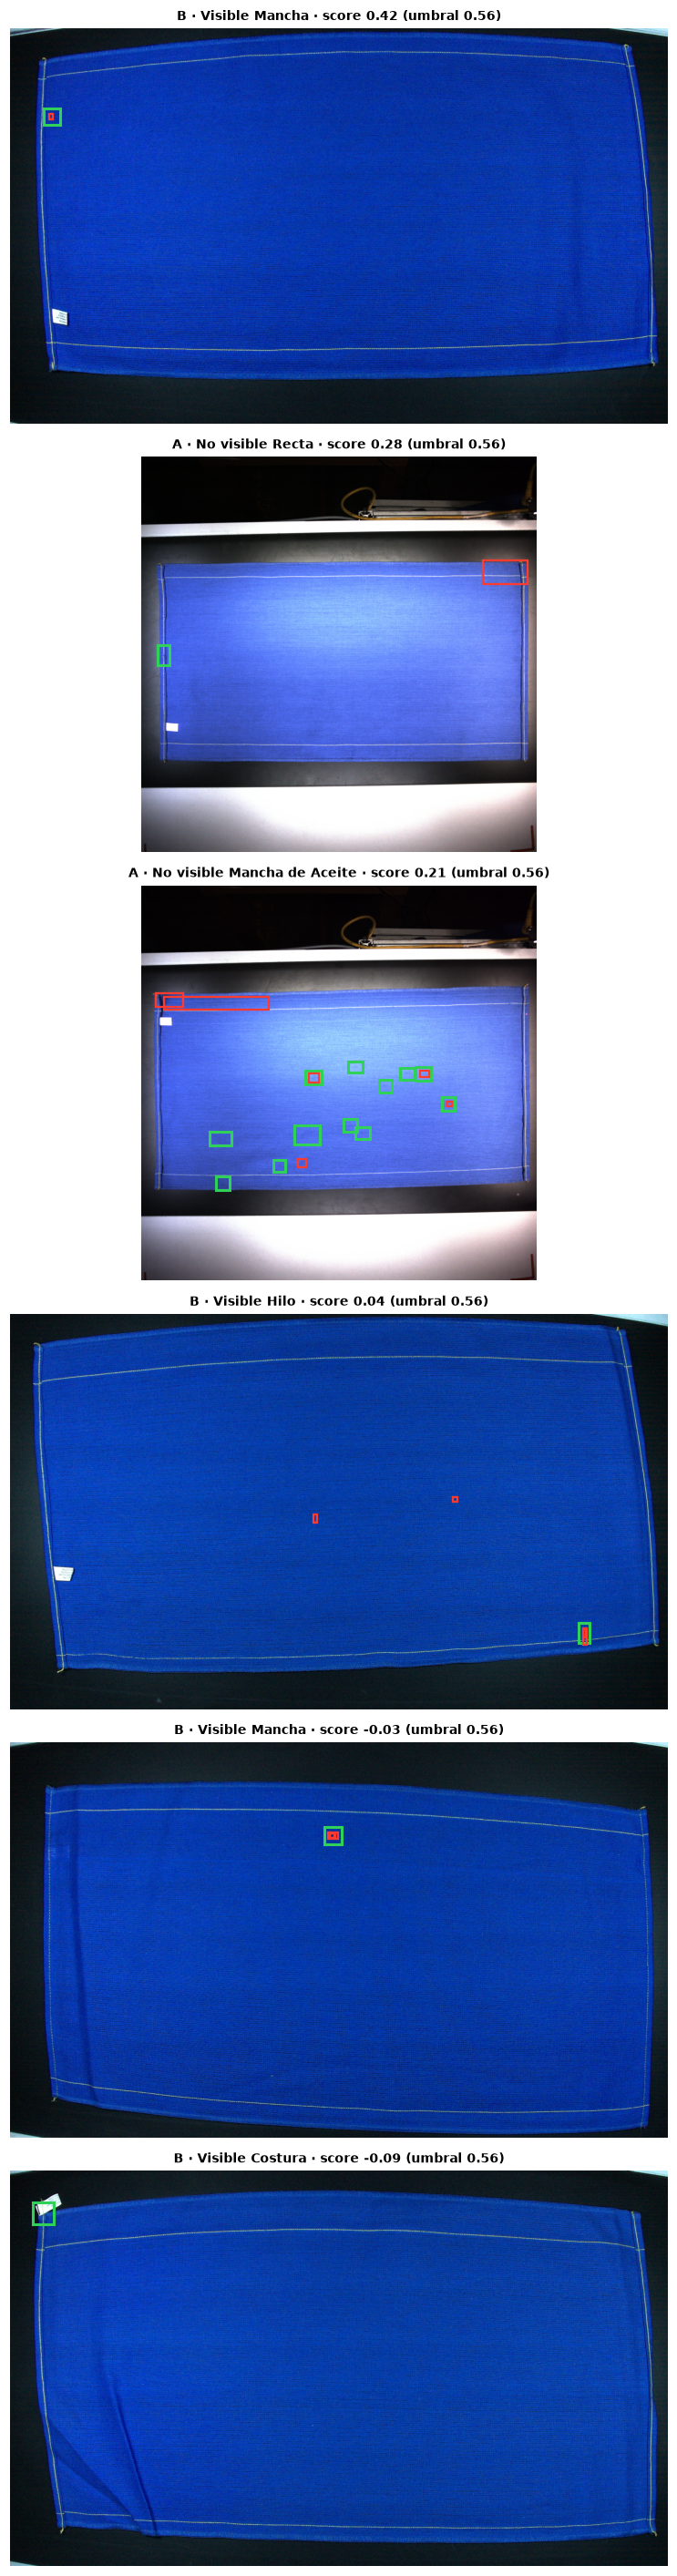

In [11]:
show = fn.sort_values("score", ascending=False).head(6)
if len(show):
    fig, axes = plt.subplots(len(show), 1, figsize=(10, 4.3 * len(show)), squeeze=False)
    for ax, r in zip(axes[:, 0], show.itertuples()):
        m = man.loc[r.image_id]
        img, s = load_image(m.path, m.source)
        ax.imshow(img); ax.set_axis_off()
        b = load_boxes(m.label_path, m.width, m.height); b[:, 1:] *= s
        for c, x1, y1, x2, y2 in b:
            if int(c) in C.DEFECT_CLASS_IDS:
                ax.add_patch(plt.Rectangle((x1 - 25, y1 - 25), x2 - x1 + 50, y2 - y1 + 50, fill=False, ec="#30d158", lw=2))
        for x1, y1, x2, y2, conf, c in dets.get(r.image_id, []):
            if conf >= 0.10 and int(c) in C.DEFECT_CLASS_IDS:
                ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="#ff3b30", lw=1.5))
        ax.set_title(f"{r.source} · {r.visibility or ''} {r.category} · score {r.score:.2f} (umbral {thr:.2f})", fontsize=9)
    plt.tight_layout()
    print("Verde: defecto anotado · Rojo: detecciones de YOLO con conf ≥ 0.10")

## 9. Falsas alarmas: toallas OK marcadas como NO OK (test)
Las de mayor score. Conviene revisarlas: a veces se trata de defectos reales que no se anotaron.

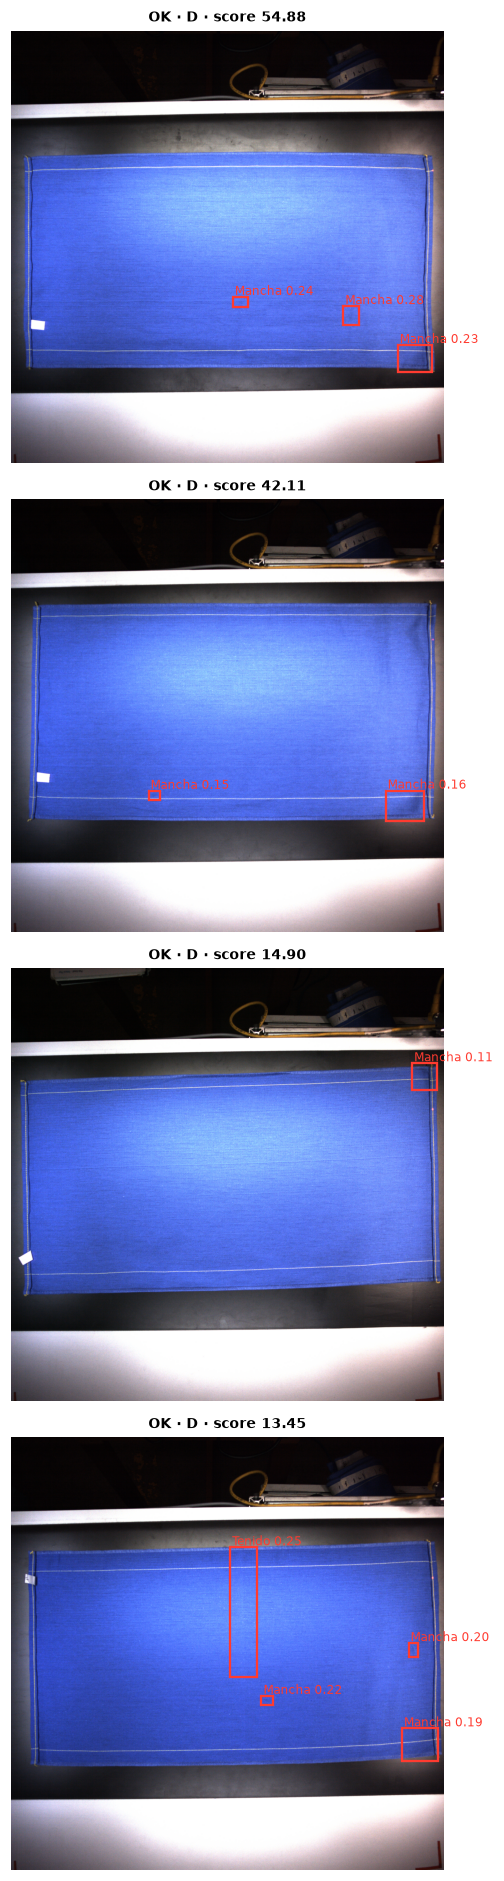

In [12]:
fp = test[(yt == 0) & pred].copy(); fp["score"] = s_sel[(yt == 0) & pred]
show = fp.sort_values("score", ascending=False).head(4)
if len(show):
    fig, axes = plt.subplots(len(show), 1, figsize=(10, 4.3 * len(show)), squeeze=False)
    for ax, r in zip(axes[:, 0], show.itertuples()):
        m = man.loc[r.image_id]
        img, s = load_image(m.path, m.source)
        ax.imshow(img); ax.set_axis_off()
        for x1, y1, x2, y2, conf, c in dets.get(r.image_id, []):
            if conf >= 0.10 and int(c) in C.DEFECT_CLASS_IDS:
                ax.add_patch(plt.Rectangle((x1 - 15, y1 - 15), x2 - x1 + 30, y2 - y1 + 30, fill=False, ec="#ff3b30", lw=1.5))
                ax.text(x1, y1 - 30, f"{C.CLASSES[int(c)]} {conf:.2f}", color="#ff3b30", fontsize=8)
        ax.set_title(f"OK · {r.source} · score {r.score:.2f}", fontsize=9)
    plt.tight_layout()

## 10. Uso en producción: una foto → decisión
```python
from galia.inference import TowelInspector
inspector = TowelInspector.from_dir("models")          # carga YOLO + clasificador + PatchCore + ensamble
r = inspector.inspect("foto_toalla.jpg")               # cámara de producción (junio 2025): scale=1.0
r["decision"], r["score"], r["defects"]
```
También existe la versión de línea de comandos: `python scripts/predict.py carpeta/ --save-images`

C:\Users\Marcony1\miniconda3\envs\galia_v2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


Decisión: NO OK · score 2.832 (umbral 0.562) · 0.63 s por toalla
Scores por modelo: {'cls': 1.0, 'yolo': 0.518}
Verde: defecto anotado · Rojo: YOLO (conf ≥ 0.10) · Color: probabilidad de defecto por recorte


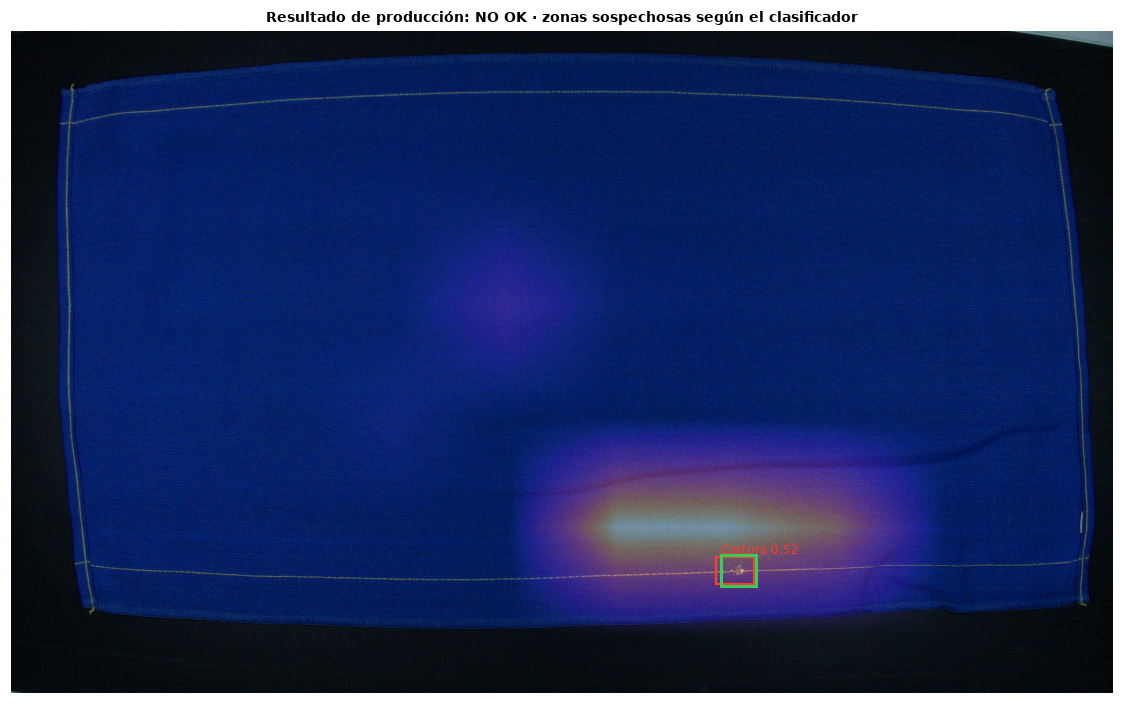

In [13]:
from galia.inference import TowelInspector
insp = TowelInspector.from_dir(C.MODELS_DIR)
r = test[(test.source == "B") & (test.label == "NG") & (test.yolo >= 0.5)].sort_values("cls", ascending=False).iloc[0]  # ejemplo detectado por ambos modelos
m = man.loc[r.image_id]
insp.inspect(m.path)  # warm-up
t0 = time.time(); out = insp.inspect(m.path, scale=C.SOURCE_SCALE[m.source]); dt = time.time() - t0
print(f"Decisión: {out['decision']} · score {out['score']:.3f} (umbral {out['threshold']:.3f}) · {dt:.2f} s por toalla")
print("Scores por modelo:", {k: round(v, 3) for k, v in out["model_scores"].items()})
img = np.asarray(__import__("PIL").Image.open(m.path).convert("RGB"))
fig, ax = plt.subplots(figsize=(11, 6.5))
viz.overlay_heatmap(ax, img, out["raw"]["cls"].heatmap, vmax=1.0, alpha=0.45,
                    title=f"Resultado de producción: {out['decision']} · zonas sospechosas según el clasificador")
for d in out["defects"]:
    if d["conf"] >= 0.10 and d["cls"] != "Etiqueta":
        x1, y1, x2, y2 = d["box"]
        ax.add_patch(plt.Rectangle((x1 - 15, y1 - 15), x2 - x1 + 30, y2 - y1 + 30, fill=False, ec="#ff3b30", lw=1.5))
        ax.text(x1, y1 - 25, f"{d['cls']} {d['conf']:.2f}", color="#ff3b30", fontsize=8)
b = load_boxes(m.label_path, m.width, m.height)
for c, x1, y1, x2, y2 in b:
    if int(c) in C.DEFECT_CLASS_IDS:
        ax.add_patch(plt.Rectangle((x1 - 25, y1 - 25), x2 - x1 + 50, y2 - y1 + 50, fill=False, ec="#30d158", lw=2))
print("Verde: defecto anotado · Rojo: YOLO (conf ≥ 0.10) · Color: probabilidad de defecto por recorte")
plt.tight_layout()